In [1]:
# %pip install -e ..

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import matplotlib.pyplot as plt



from vlasov.config import Grid
from vlasov.initial_conditions import landau_damping, bump_on_tail
from vlasov.solver import run

# Experiment configuration
grid = Grid(
    xmin=0,
    xmax=4*np.pi,
    nx=1024,
    vmin=-6,
    vmax=6,
    nv=128,
)

dt = 0.6
nsteps = 200

# Initial condition
f0 = bump_on_tail(
    grid, epsilon=0.001, kx=0.5
)

# Simulation
f_final, energy, totrho,totenergy = run(f0, grid, dt, nsteps)

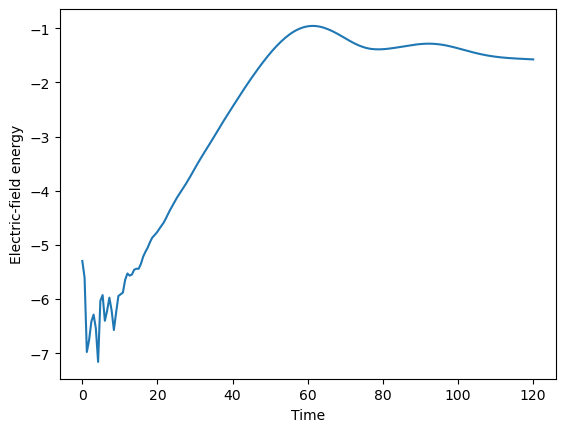

In [4]:


# Analysis
times = np.arange(nsteps + 1) * dt

plt.plot(times, energy)
plt.xlabel("Time")
plt.ylabel("Electric-field energy")
plt.show()

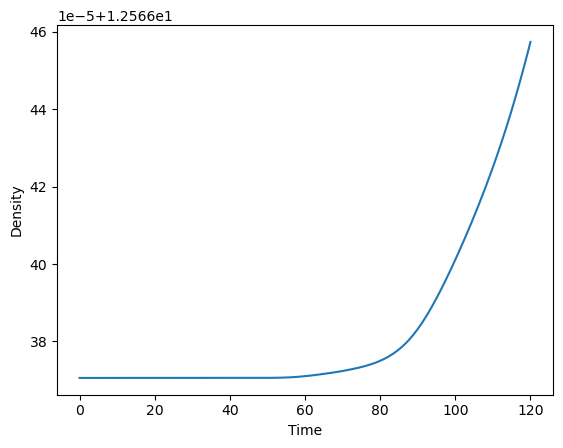

Initial density: 12.566370591436813
Final density: 12.566457351064575
Absolute change: 8.675962776116819e-05
Relative change: 6.904111822095187e-06


In [5]:
plt.plot(times, totrho)
plt.xlabel("Time")
plt.ylabel("Density")
plt.show()
print("Initial density:", totrho[0])
print("Final density:", totrho[-1])
print("Absolute change:", abs(totrho[-1] - totrho[0]))
print("Relative change:", abs(totrho[-1] - totrho[0]) / abs(totrho[0]))

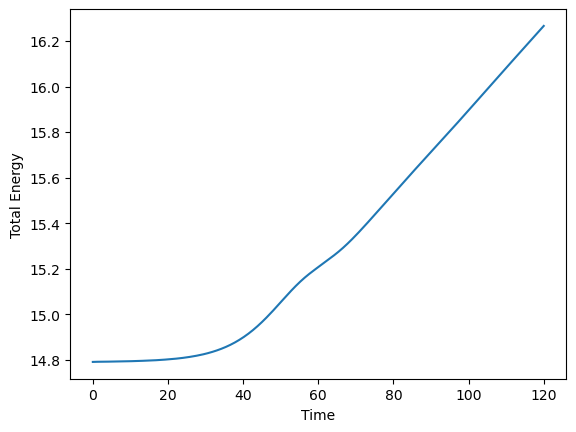

In [6]:

plt.plot(times, totenergy)
plt.xlabel("Time")
plt.ylabel("Total Energy")
plt.show()

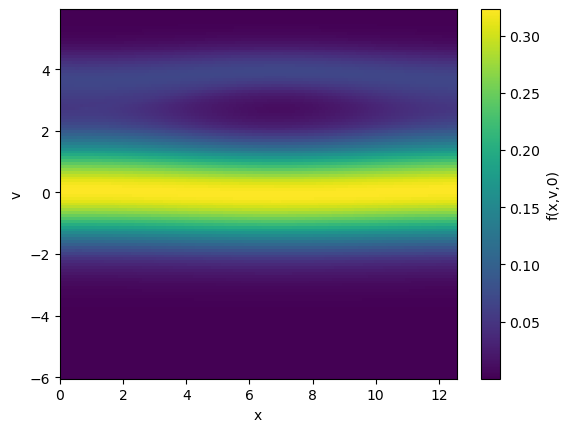

In [7]:
plt.pcolormesh(grid.x, grid.v, f_final[-1].T, shading="auto")
plt.xlabel("x")
plt.ylabel("v")
plt.colorbar(label="f(x,v,0)")
plt.show()

In [8]:
from vlasov.numerics import cubic_interpolate

f_final, energy, totrho,totenergy = run(f0, grid, dt, nsteps,cubic_interpolate,cubic_interpolate)

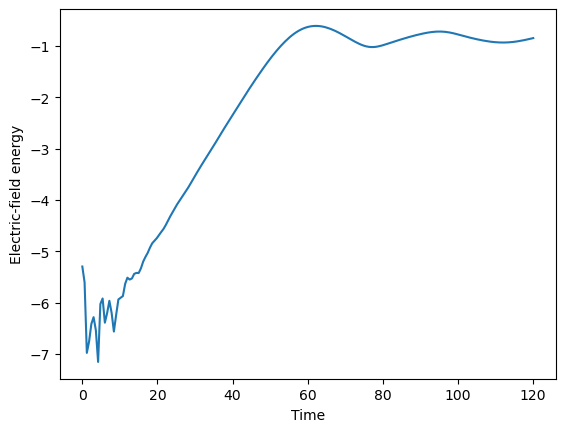

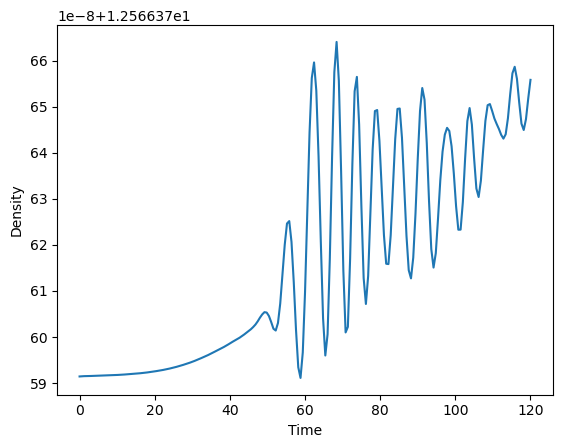

Initial density: 12.566370591436813
Final density: 12.5663706558311
Absolute change: 6.439428723581386e-08
Relative change: 5.124334569576875e-09


In [9]:
plt.plot(times, energy)
plt.xlabel("Time")
plt.ylabel("Electric-field energy")
plt.show()

plt.plot(times, totrho)
plt.xlabel("Time")
plt.ylabel("Density")
plt.show()
print("Initial density:", totrho[0])
print("Final density:", totrho[-1])
print("Absolute change:", abs(totrho[-1] - totrho[0]))
print("Relative change:", abs(totrho[-1] - totrho[0]) / abs(totrho[0]))

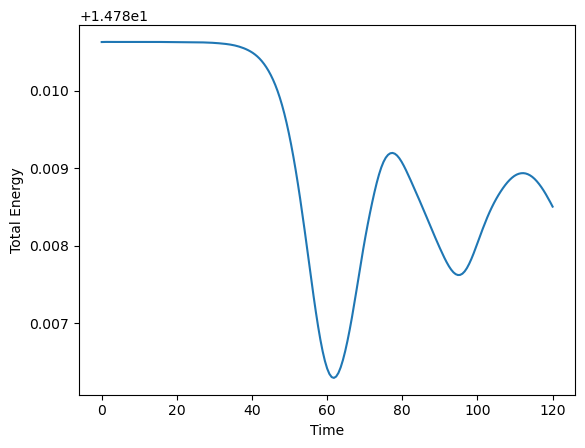

Initial Total Energy: 14.790630345695256
Final Total Energy: 14.788506171172891
Absolute change: 0.0021241745223647968
Relative change: 0.00014361622680827987


In [10]:

plt.plot(times, totenergy)
plt.xlabel("Time")
plt.ylabel("Total Energy")
plt.show()

print("Initial Total Energy:", totenergy[0])
print("Final Total Energy:", totenergy[-1])
print("Absolute change:", abs(totenergy[-1] - totenergy[0]))
print("Relative change:", abs(totenergy[-1] - totenergy[0]) / abs(totenergy[0]))

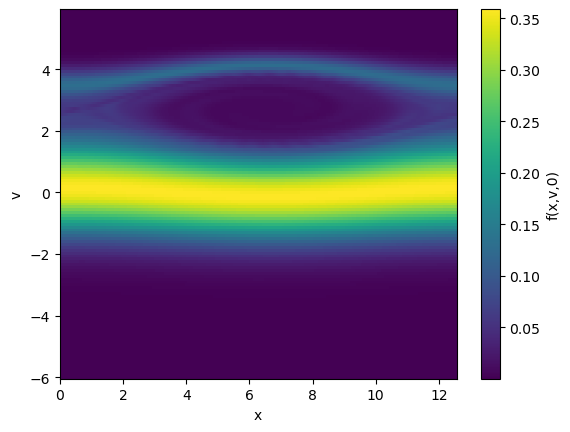

In [11]:
plt.pcolormesh(grid.x, grid.v, f_final[-1].T, shading="auto")
plt.xlabel("x")
plt.ylabel("v")
plt.colorbar(label="f(x,v,0)")
plt.show()

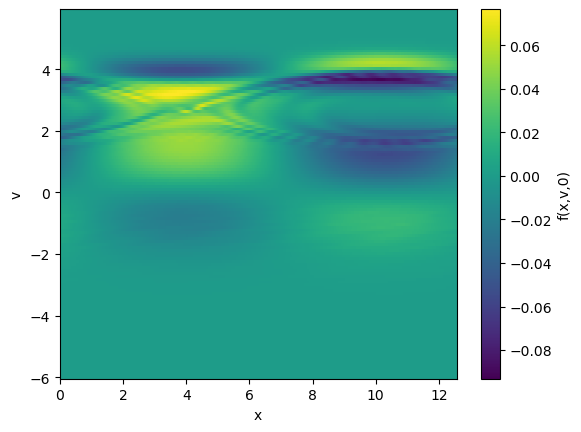

In [12]:
plt.pcolormesh(grid.x, grid.v, f_final[140].T-f_final[0].T, shading="auto")
plt.xlabel("x")
plt.ylabel("v")
plt.colorbar(label="f(x,v,0)")
plt.show()